# Difference-in-Differences (DiD)

*Companion notebook — Quasi-Experimental Methods for Business Interventions in Python. Self-contained: run the setup cells first.*

In [ ]:
# Install dependencies (Colab/Jupyter)
%pip install -q numpy pandas matplotlib seaborn statsmodels linearmodels scikit-learn scipy doubleml econml dowhy tfp-causalimpact pysyncon rdrobust

## Setup: shared imports and data generators

This cell reproduces the book's `_common.py` so the notebook runs standalone.

In [2]:
"""Shared setup for all chapters: imports, plotting theme, and data generators."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


def make_panel(
    n_stores=120,
    n_markets=12,
    n_weeks=104,                # 2 years of weekly data
    treat_markets=(0, 1, 2, 3), # which markets get the program
    treat_week=60,              # program launch week
    true_effect=8.0,            # true lift in weekly revenue ($k)
    effect_ramp=6,              # weeks for the effect to reach full size
    seed=42,
):
    """NorthShore Retail store-week panel with known treatment effect."""
    rng = np.random.default_rng(seed)
    stores = np.arange(n_stores)
    markets = stores % n_markets
    store_fe = rng.normal(100, 15, n_stores)
    market_fe = rng.normal(0, 8, n_markets)
    store_trend = rng.normal(0.05, 0.03, n_stores)

    rows = []
    market_shock = rng.normal(0, 3, (n_markets, n_weeks))
    for w in range(n_weeks):
        season = 6 * np.sin(2 * np.pi * w / 52)
        for s in stores:
            m = markets[s]
            treated_unit = m in treat_markets
            post = w >= treat_week
            if treated_unit and post:
                ramp = min(1.0, (w - treat_week + 1) / effect_ramp)
                tau = true_effect * ramp
            else:
                tau = 0.0
            y = (store_fe[s] + market_fe[m] + store_trend[s] * w
                 + season + market_shock[m, w]
                 + tau + rng.normal(0, 4))
            rows.append((s, m, w, int(treated_unit), int(post),
                         int(treated_unit and post), y))

    return pd.DataFrame(rows, columns=[
        "store", "market", "week", "treated", "post", "D", "revenue"])


def make_customers(n=8000, true_att=12.0, seed=42):
    """Loyalty-program adoption data with selection on observables."""
    rng = np.random.default_rng(seed)
    tenure = rng.gamma(3, 1.2, n)
    spend0 = rng.lognormal(4.0, 0.5, n)
    engage = rng.beta(2, 5, n) * 10
    urban = rng.binomial(1, 0.55, n)
    logit = -3.0 + 0.25*tenure + 0.004*spend0 + 0.30*engage + 0.4*urban
    p = 1 / (1 + np.exp(-logit))
    D = rng.binomial(1, p)
    y = (0.55*spend0 + 4*tenure + 2.5*engage + 6*urban
         + true_att * D + rng.normal(0, 12, n))
    return pd.DataFrame(dict(tenure=tenure, spend0=spend0, engage=engage,
                             urban=urban, D=D, y=y))


panel = make_panel()
cust = make_customers()
X_cols = ["tenure", "spend0", "engage", "urban"]
TRUE_ATT = 12.0


**Business setting:** the Fresh Local program launched in 4 of 12 markets at a single point in time. We have pre- and post-period outcomes for both treated and untreated markets.

## Logic

DiD removes two kinds of bias at once:

1. **Level differences** between treated and control groups (flagship markets are just bigger) — differenced out by comparing each group to its own pre-period.
2. **Common time shocks** (seasonality, macro conditions, company-wide changes) — differenced out by subtracting the control group's change.

$$
\hat{\tau}_{DiD} = \big(\bar{Y}^{T}_{post} - \bar{Y}^{T}_{pre}\big) - \big(\bar{Y}^{C}_{post} - \bar{Y}^{C}_{pre}\big)
$$

**Identifying assumption — parallel trends:** absent the program, treated-market revenue would have evolved in parallel with control-market revenue. Level differences are fine; differential *trends* are fatal.

## The 2×2 by hand

In [3]:
# Group the data by whether the market was treated and whether it's the pre- or post-period,
# then calculate the mean revenue for each group.
g = (panel.groupby(["treated", "post"]).revenue.mean()
          .unstack("post"))

# Rename the columns for clarity: "pre" for pre-period, "post" for post-period.
g.columns = ["pre", "post"]

# Compute the change in revenue from pre-period to post-period for each group (treated/control).
g["change"] = g["post"] - g["pre"]

# Display the summary table with average revenues and their changes.
print(g)

# Compute the Difference-in-Differences (DiD) estimate:
# The change in the treated group minus the change in the control group.
did_2x2 = g.loc[1, "change"] - g.loc[0, "change"]

# Print the DiD estimate, which approximates the treatment effect.
print(f"\n2x2 DiD estimate: {did_2x2:.2f}")

            pre    post  change
treated                        
0        99.069 101.205   2.136
1       101.875 110.678   8.803

2x2 DiD estimate: 6.67


Note this will land somewhat below 8 because the effect ramps in over 6 weeks — the post-period *average* effect is diluted by the ramp. This is a realistic feature: business interventions rarely hit full strength instantly, and the event-study plot in Section 5 makes the ramp visible.

## Regression DiD with two-way fixed effects (TWFE)

The regression form generalizes the 2×2, allows covariates, and produces standard errors:

$$
Y_{it} = \alpha_i + \lambda_t + \tau \, D_{it} + \varepsilon_{it}
$$

where $\alpha_i$ are store fixed effects, $\lambda_t$ week fixed effects, and $D_{it}$ is the store-week treatment indicator.

In [5]:
# Import the PanelOLS regression model from the linearmodels package.
from linearmodels.panel import PanelOLS

# Set the index of the DataFrame to be a MultiIndex of store and week,
# which is the standard format for panel data regressions.
pdf = panel.set_index(["store", "week"])

# Specify and set up the Difference-in-Differences regression.
# The regression formula is:
#   revenue ~ D + EntityEffects + TimeEffects
# where:
#   - 'D' is an indicator for treated store-weeks (treatment group after the program starts)
#   - 'EntityEffects' adds a fixed effect for each store (controls for all time-invariant differences between stores)
#   - 'TimeEffects' adds a fixed effect for each week (controls for time shocks affecting all stores equally)
mod = PanelOLS.from_formula(
    "revenue ~ D + EntityEffects + TimeEffects", data=pdf
)

# Fit the model to the data, clustering standard errors by 'market'.
# Clustering accounts for within-market correlation of errors, which is crucial when treatment is assigned at the market level.
res = mod.fit(cov_type="clustered", clusters=pdf["market"])

# Print the regression summary table containing the estimated coefficients and standard errors.
print(res.summary.tables[1])

                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
D              6.6675     0.5651     11.799     0.0000      5.5598      7.7752


**Three practical points:**

- **Cluster the standard errors at the level of treatment assignment** — here, the *market*, not the store. Treatment varies at the market level, so store-level errors within a market are correlated; clustering at the store level would dramatically overstate precision (Bertrand, Duflo & Mullainathan 2004). With few clusters (< ~40), use wild-cluster bootstrap (`wildboottest` package) or aggregate to the market level.
- **Few treated clusters is a real problem.** With 4 treated markets, asymptotic clustered SEs are unreliable. Randomization/permutation inference (Section 8's placebo logic) is a good complement.
- **Covariates** should be pre-treatment or time-invariant. Never add post-treatment variables (mediators).

## Testing (really, *probing*) parallel trends

Parallel trends cannot be tested directly — it is a statement about an unobserved counterfactual. But pre-period trends are observable, and divergence before launch is a red flag.

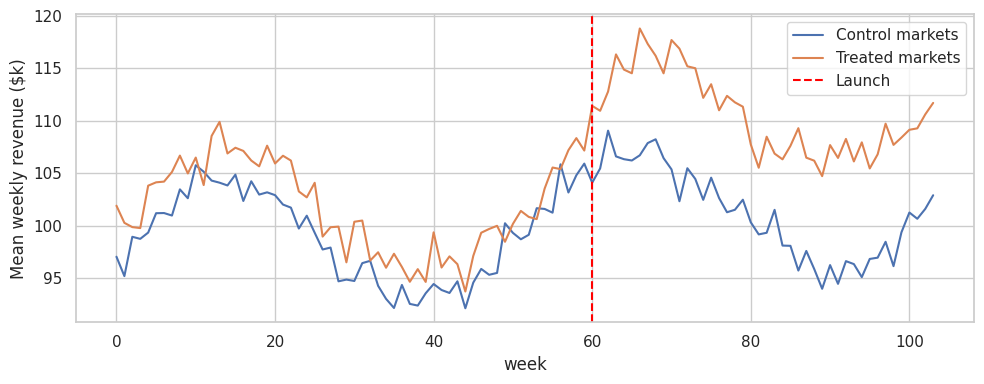

In [7]:
# Compute the mean weekly revenue for control and treated markets by week.
# This groups the panel data by 'week' and 'treated', calculates the mean revenue for each group,
# and rearranges the results so columns represent 'treated' (0=control, 1=treated) and rows are weeks.
trend = (panel.groupby(["week", "treated"]).revenue.mean()
              .unstack("treated"))

# Plot the time series of mean revenue for both control and treated groups.
ax = trend.plot(figsize=(10, 4))

# Add a vertical red dashed line at week 60 to indicate the program launch.
ax.axvline(60, color="red", ls="--", label="launch")

# Label the Y axis.
ax.set_ylabel("Mean weekly revenue ($k)")

# Add a legend to clarify each line represents control or treated groups, plus the launch.
ax.legend(["Control markets", "Treated markets", "Launch"])

# Adjust layout to prevent overlap and display the plot.
plt.tight_layout()
plt.show()

Formal pre-trend check — interact `treated` with a linear pre-period trend:

In [9]:
# Restrict the data to the pre-treatment period (weeks before the program launch at week 60)
pre = panel.query("week < 60").copy()

# Run a regression of revenue on treatment status, time, their interaction, and market fixed effects
# This estimates whether the pre-period trend differs for treated and control groups; 
# clustering standard errors at the market level acknowledges within-market correlation
m_pre = smf.ols("revenue ~ treated * week + C(market)", data=pre).fit(
    cov_type="cluster", cov_kwds={"groups": pre["market"]})

# Print the estimated coefficient and p-value for the interaction term 'treated:week'
# A significant, nonzero value would indicate divergent pre-trends (parallel trends violated)
print(m_pre.params["treated:week"], m_pre.pvalues["treated:week"])

-0.021978982980827268 0.16695208074469803


A near-zero, insignificant interaction is reassuring but not proof; a significant one means plain DiD is off the table (consider synthetic control, Section 8, or conditioning trends on covariates). Also beware the modern critique (Roth 2022): pre-trend *tests* have low power, and passing one doesn't license certainty. Report the event-study plot and consider Rambachan–Roth style sensitivity ("how much trend violation would overturn the result?" — Section 13).

## Common business pitfalls

- **Anticipation.** If stores ramped up staffing or customers delayed purchases before launch ("wait for the remodel sale"), the pre-period is contaminated. Drop a buffer window before launch or date treatment from the announcement.
- **Spillovers.** If the campaign's media bleeds into adjacent control markets, controls are partially treated and DiD is biased toward zero. Choose geographically distant controls, or model exposure intensity.
- **Composition change.** If the program changes which stores stay open or which customers are in the data, you're comparing different populations. Use a balanced panel where defensible, and analyze attrition explicitly.
- **Log vs. levels.** Parallel trends in levels and in logs are different assumptions. Pick the scale in which "parallel" is economically plausible (often logs for revenue, since shocks tend to be proportional) and say so.